# Lepton-jet reconstruction efficiency, step 1: where it comes from, in simulation

Step 1 of the plan in [`lj_reco_efficiency.md`](lj_reco_efficiency.md), in simulation only:
for every dark photon decaying to muons (electrons), the efficiency to find a muon-type
(egamma-type) lepton jet within $\Delta R < 0.4$, against the decay radius $L_{xy}$, the dark
photon $p_T$ and the opening angle $\Delta R(\ell, \ell)$ of its two leptons, over the whole
signal grid. It shows which regime each signal point depends on, which decides the control
samples of step 2 and how to weight them per point. Steps 2 and 3 are not done here, and the
questions to the group stay open (last section).

**The efficiency** is that of the chain in `sidm/studies/ljRecoEffi_studies`, reused as it is:

* denominator, channel `baseNoLj_A_mumu` (`baseNoLj_A_ee`): every generator dark photon decaying
  to muons (electrons), in events that pass the base selection before lepton jets (triggers,
  a good vertex, two muons above 26 GeV, the cosmic veto);
* numerator, `baseNoLj_A_mumu_matched_lj` (`baseNoLj_A_ee_matched_lj`): those within
  $\Delta R < 0.4$ of a lepton jet ($p_T$ > 30 GeV, $|\eta|$ < 2.4), in events with at least one
  dark photon matched to a selected muon-type (egamma-type) lepton jet.

No isolation, displacement or category cut is applied: this is the efficiency to reconstruct
a lepton jet, not to select the event. The muon-type efficiency is measured in the 2mu2e and
in the 4mu samples, the egamma-type one in the 2mu2e samples. The opening angle comes from the
per-dark-photon map of $L_{xy}$ against $\Delta R(\ell, \ell)$.

**Inputs:** the merged outputs of the campaign `lj_reco_eff_v1`
(`condor/campaign_configs/lj_reco_eff_v1.yaml`): all 180 signal points, weighted histograms,
no corrections. **Simulation only.** The figures and a table of the efficiency per point go to
EOS, next to the inputs (`lj_reco_eff_v1_results/`), read and written through xrootd so the
notebook runs at the LPC and on CoffeaCasa alike.

**Interpretations.** Each section ends with an interpretation of its results and of what they
mean for the analysis, written for the run named in it. Revise them when a rerun changes the
picture.

In [1]:
import os, shutil, sys, tempfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities
from sidm.studies.corrections import corrections_study as study
from sidm.studies.systematics import systematics_study as sysstudy

warnings.filterwarnings("ignore", module="coffea")
utilities.set_plot_style(dpi=100)

INPUT_DIR = sysstudy.eos_url(sysstudy.LJ_RECO_DIR)   # the merged outputs of lj_reco_eff_v1
OUTPUT_DIR = f"{INPUT_DIR}_results"                  # figures and the table per point
if not sysstudy.list_coffea(INPUT_DIR):
    raise FileNotFoundError(
        f"No merged outputs in {INPUT_DIR} yet. Run the lj_reco_eff_v1 campaign first, from the "
        "repository root: python condor/campaign.py lj_reco_eff_v1 jobs, then submit, then status "
        "with retry --submit and skipped --submit until every chunk is done, then merge "
        "(condor/README.md, section 23).")
WORK = Path(tempfile.mkdtemp(prefix="lj_reco_eff_v1_"))   # removed at the end
# (final state, lepton-jet type): the efficiencies this notebook measures
CASES = [("2Mu2E", "muon-type"), ("4Mu", "muon-type"), ("2Mu2E", "egamma-type")]


def save(fig, name):
    """Write a figure into the working directory, for EOS, as PDF and PNG"""
    for suffix in (".pdf", ".png"):
        fig.savefig(WORK / f"{name}{suffix}", bbox_inches="tight")


print("inputs: ", INPUT_DIR)
print("outputs:", OUTPUT_DIR)

inputs:  root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_eff_v1
outputs: root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_eff_v1_results


## 1. Inputs

One pass over the merged outputs, keeping the histograms of the efficiency channels
(`systematics_study.lj_efficiency_inputs`), and the efficiency of every point.

In [2]:
inputs = sysstudy.lj_efficiency_inputs(INPUT_DIR)
points = {fs: sysstudy.ordered_points(list(inputs), fs) for fs in ("2Mu2E", "4Mu")}
# lifetimes are ranked on the full grid, so the limit grid is taken from it
LIMIT = set(sysstudy.limit_grid(study.signal_points())) & set(inputs)
print({fs: len(p) for fs, p in points.items()}, "signal points,", len(LIMIT), "on the limit grid\n")

print(f"{'samples':8s} {'lepton jet':12s} {'median':>8s} {'min':>8s} {'max':>8s}   efficiency per point (all points)")
for fs, lj_type in CASES:
    effs = [sysstudy.regime_fractions(*inputs[s][lj_type]["lxy"])[0] for s in points[fs] if lj_type in inputs[s]]
    print(f"{fs:8s} {lj_type:12s} {np.median(effs):8.3f} {min(effs):8.3f} {max(effs):8.3f}")

{'2Mu2E': 90, '4Mu': 90} signal points, 96 on the limit grid

samples  lepton jet     median      min      max   efficiency per point (all points)
2Mu2E    muon-type       0.976    0.687    0.996
4Mu      muon-type       0.846    0.427    0.974
2Mu2E    egamma-type     0.710    0.207    0.937


## 2. Efficiency against $L_{xy}$, $p_T$ and the opening angle

All signal points of a final state together, one curve per dark photon mass. The points are
summed as counts of simulated dark photons (`systematics_study.summed`), so each dark photon
counts once whatever the cross section of its point: every event of a signal sample carries
the same weight, and a sum weighted by cross section would be dominated by the lightest bound
states. The error bars are Clopper-Pearson intervals (`utilities.get_eff_hist`). The
$L_{xy}$ histograms end at 500 cm (muons) and 150 cm (electrons); the maps of section 3 reach
500 cm for both.

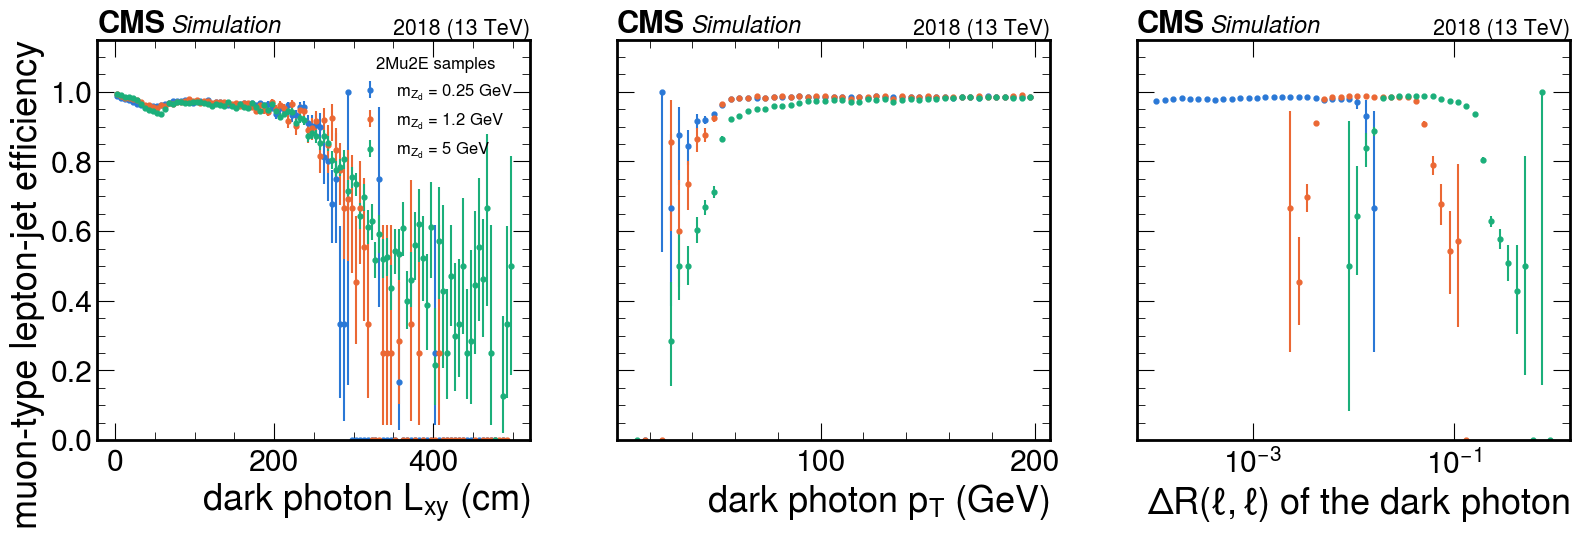

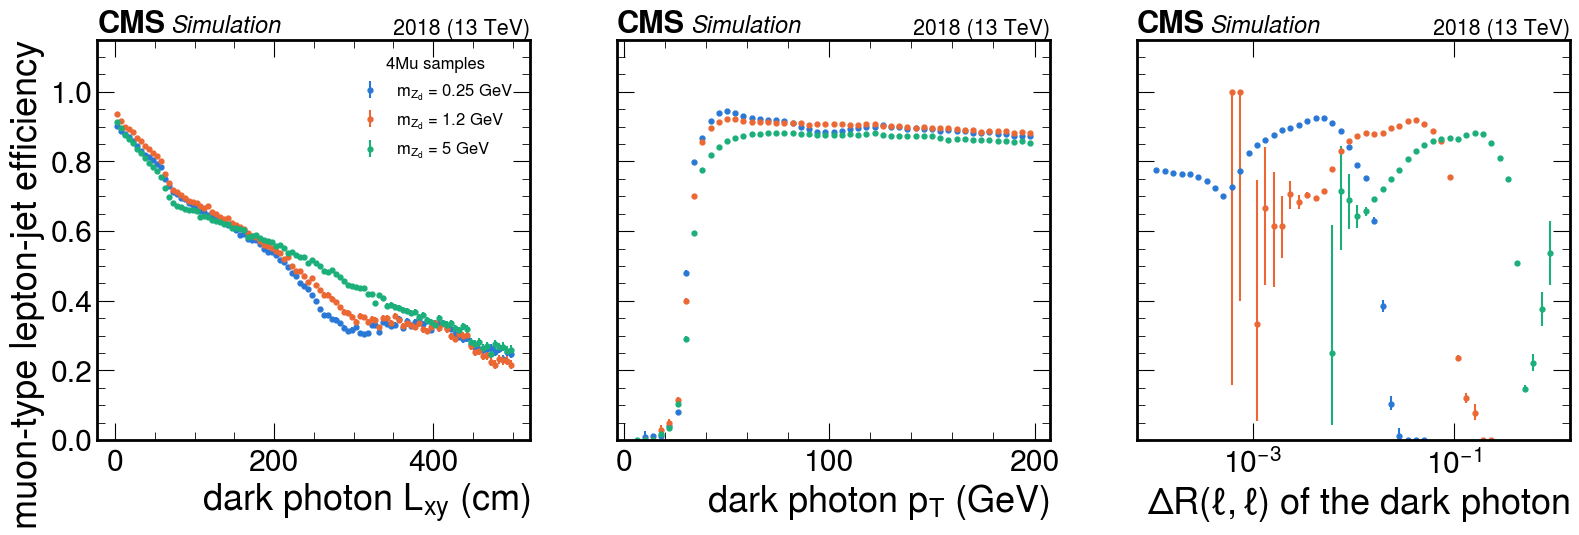

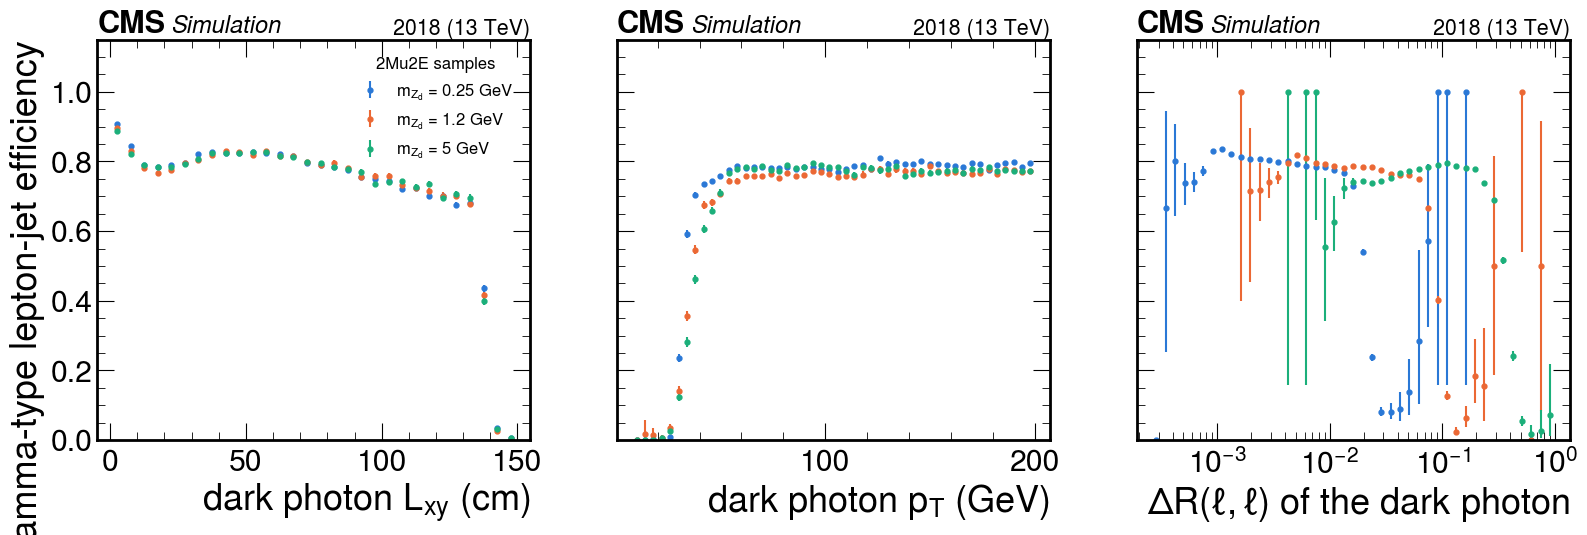

In [3]:
MZD = {0.25: "0.25 GeV", 1.2: "1.2 GeV", 5.0: "5 GeV"}
for fs, lj_type in CASES:
    groups = {rf"$m_{{Z_d}}$ = {label}": [s for s in points[fs] if study.parse_point(s)["m_zd"] == mzd]
              for mzd, label in MZD.items()}
    fig = sysstudy.plot_lj_efficiency(inputs, groups, lj_type, title=f"{fs} samples")
    save(fig, f"efficiency_{lj_type}_{fs}")
    plt.show()

**Interpretation (run of 2026-11-14: `lj_reco_eff_v1`, 180 signal points).**

*Muon-type, 4Mu samples.* The efficiency falls steadily with the decay radius: 0.91 for
$L_{xy}$ < 10 cm, 0.82 from 10 to 100 cm, 0.62 from 100 to 200 cm and 0.33 from 300 to 500 cm
(all points summed). Against $p_T$ it turns on with the lepton-jet threshold of 30 GeV, peaks at
0.88 to 0.94 between 50 and 75 GeV (lower for heavier dark photons) and falls slowly to 0.85 to
0.88 at 200 GeV. The projection on the opening angle mixes points of different masses and
lifetimes, so its structure is not a dependence on $\Delta R$ alone; section 3 separates the
two.

*Muon-type, 2Mu2E samples.* The efficiency stays at 0.97 to 0.99 out to $L_{xy}$ = 200 cm and
falls beyond (0.93 from 200 to 250 cm, 0.52 from 300 to 500 cm). This is not a better
reconstruction. The base selection requires two PF or DSA muons above 26 GeV, and a 2mu2e signal
event has no muons other than the two of its muon dark photon, so every dark photon in this
denominator already has both muons reconstructed: the ratio measures only the clustering into a
lepton jet and the lepton-jet cuts. On the same points of the limit grid, the 4Mu efficiency
(where the other dark photon can provide the two muons) is 0.90, 0.81 and 0.52 for $L_{xy}$
below 10 cm, from 10 to 100 cm and beyond 100 cm, against 0.99, 0.97 and 0.96 in 2Mu2E (medians
over the 48 points, and over the 36 with more than 50 simulated dark photons beyond 100 cm).

*Egamma-type, 2Mu2E samples.* 0.89 below 10 cm, 0.80 from 10 to 100 cm and 0.69 from 125 to
135 cm, then 0.42 from 135 to 140 cm and 0.02 beyond: egamma-type lepton jets end where the
ECAL starts (its barrel front face is at 129 cm). The plateau above 60 GeV is at about 0.78.
The base selection asks nothing of electrons, so this efficiency is not conditioned the way the
2Mu2E muon-type one is.

**For the analysis:** the muon-type efficiency of the 2Mu2E samples is not the probability that
a muon dark photon gives a lepton jet; most of its dependence on the decay radius sits in the
base selection. A data/simulation difference in the reconstruction of displaced muons changes
the 2mu2e yield through the base selection. The muon-type scale factor therefore has to be
measured without that condition (as the control samples of step 2 would be) and applied to the
muon-type lepton jet of the 2mu2e events too, which the per-lepton-jet weight of the plan does.
The size of the effect, and any provisional value, should be judged on the 4Mu curve, not on
the 2Mu2E one.

## 3. The efficiency in the plane of $L_{xy}$ and the opening angle

All signal points of a final state together, summed as in section 2. Blank bins hold fewer
than two simulated dark photons.

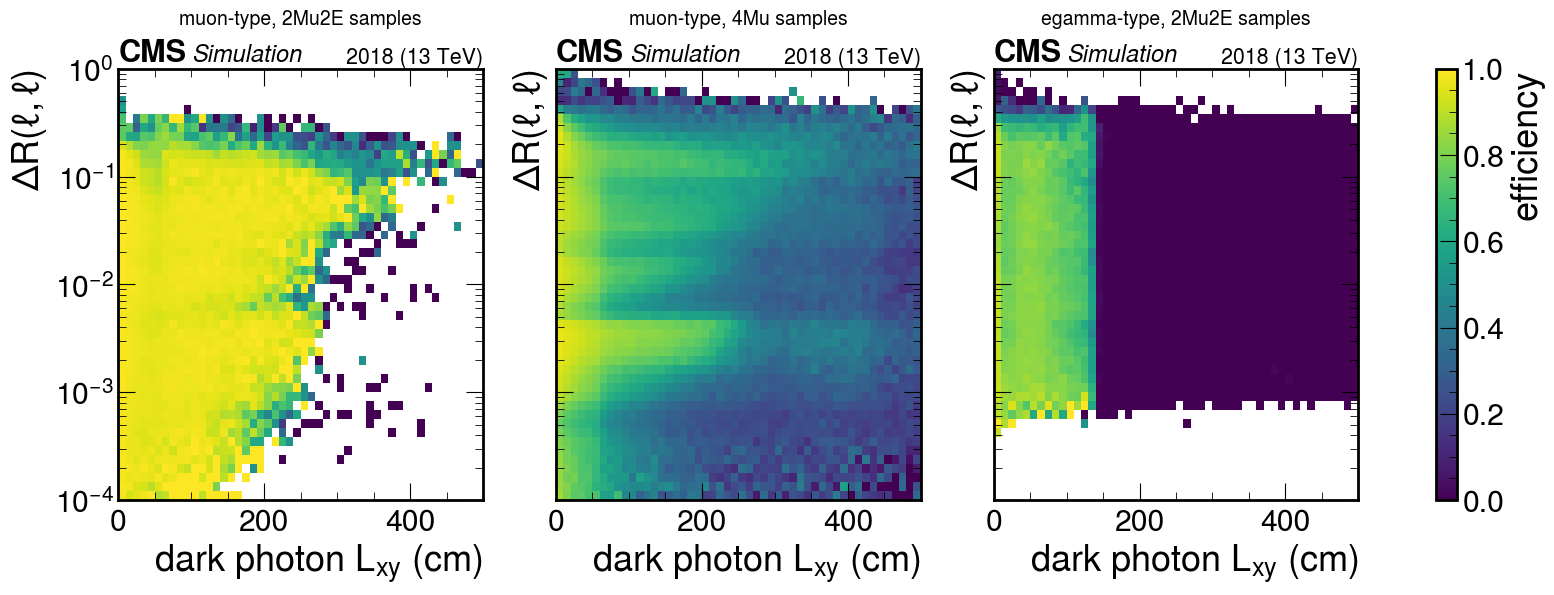

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.6), sharey=True)
for ax, (fs, lj_type) in zip(axes, CASES):
    mesh = sysstudy.plot_lj_efficiency_map(inputs, points[fs], lj_type, ax)
    ax.set_title(f"{lj_type}, {fs} samples", fontsize=14, pad=32)   # above the CMS label
fig.colorbar(mesh, ax=list(axes), label="efficiency")
study.cms_label(axes)
save(fig, "efficiency_maps")
plt.show()

**Interpretation (run of 2026-11-14).**

*Muon-type, 2Mu2E samples.* Close to 1 over the whole populated plane, except near the
lepton-jet cone ($\Delta R$ above 0.2 to 0.3, light bound states with $m_{Z_d}$ = 5 GeV) and
beyond 250 cm. The empty corner at large $L_{xy}$ and small $\Delta R$ is the base selection
again. The two final states have the same dark photon kinematics, and the 2Mu2E denominator
holds 0.14 times as many muon dark photons as the 4Mu one below 10 cm and 0.13 times from 10 to
100 cm, but only 0.002 times beyond 250 cm with $\Delta R$ < 0.01: collimated muons from decays
that far out are rarely reconstructed as two muons above 26 GeV, so those 2mu2e events never
enter the denominator.

*Muon-type, 4Mu samples.* The efficiency falls with $L_{xy}$ at every opening angle. The
horizontal bands are signal points ($\Delta R \approx 4 m_{Z_d}/m_\Phi$), and they differ at the
same $L_{xy}$ and $\Delta R$, so the efficiency depends on more than these two variables. For
$L_{xy}$ < 10 cm it is 0.92 to 0.97 for bound states up to 500 GeV, 0.87 to 0.92 at 800 GeV and
0.77 to 0.89 at 1000 GeV, lowest for $m_{Z_d}$ = 0.25 GeV, whose muons are only 0.0006 to 0.0007
apart in $\Delta R$. In 2Mu2E the same dark photons are at 0.98 to 0.99, conditioned as above.
Part of the spread between points can come from the base selection, which conditions the 4Mu
efficiency too, less strongly.

*Egamma-type, 2Mu2E samples.* Nearly flat in $\Delta R$ from 0.001 to 0.2 at a given $L_{xy}$,
and zero beyond 140 cm at every opening angle. For bound states of 150 GeV and more the prompt
efficiency ($L_{xy}$ < 10 cm) is 0.86 to 0.92 at every $m_{Z_d}$; only the 100 GeV points are
lower (0.54 to 0.64), in the turn-on of the 30 GeV threshold.

**For the analysis:** for egamma-type lepton jets, $L_{xy}$ (and $p_T$ near the threshold)
describes the efficiency well, so a scale factor against conversion radius and $p_T$, as the
Z → μμγ row of the plan proposes, transfers between signal points. For muon-type lepton jets a
scale factor binned in $L_{xy}$ alone would not transfer exactly between points: it needs $p_T$
or the opening angle as well, as the J/ψ row of the plan proposes. The heaviest bound states
with the lightest dark photon ($\Delta R$ below about 0.001: $m_{Z_d}$ = 0.25 GeV at 800 and
1000 GeV, 8 points of the limit grid per final state) have the lowest prompt efficiency, and no
control sample of the plan reaches that opening angle: a J/ψ would need a $p_T$ of about 6 TeV
for $\Delta R$ = 0.001. This is a new question for the group (section 5).

## 4. Per signal point: the efficiency, and where the lepton jets come from

For every point of the limit grid, the efficiency (top) and the fraction of its matched dark
photons that decay inside the pixel layers ($L_{xy}$ < 10 cm), in the strip tracker (10 to
100 cm) and beyond the tracker (100 cm and more), the regimes of the plan. These fractions are
the weights with which a regime-dependent measurement of step 2 would enter each point. The
table of all 180 points goes to EOS (`efficiency_regimes.csv`).

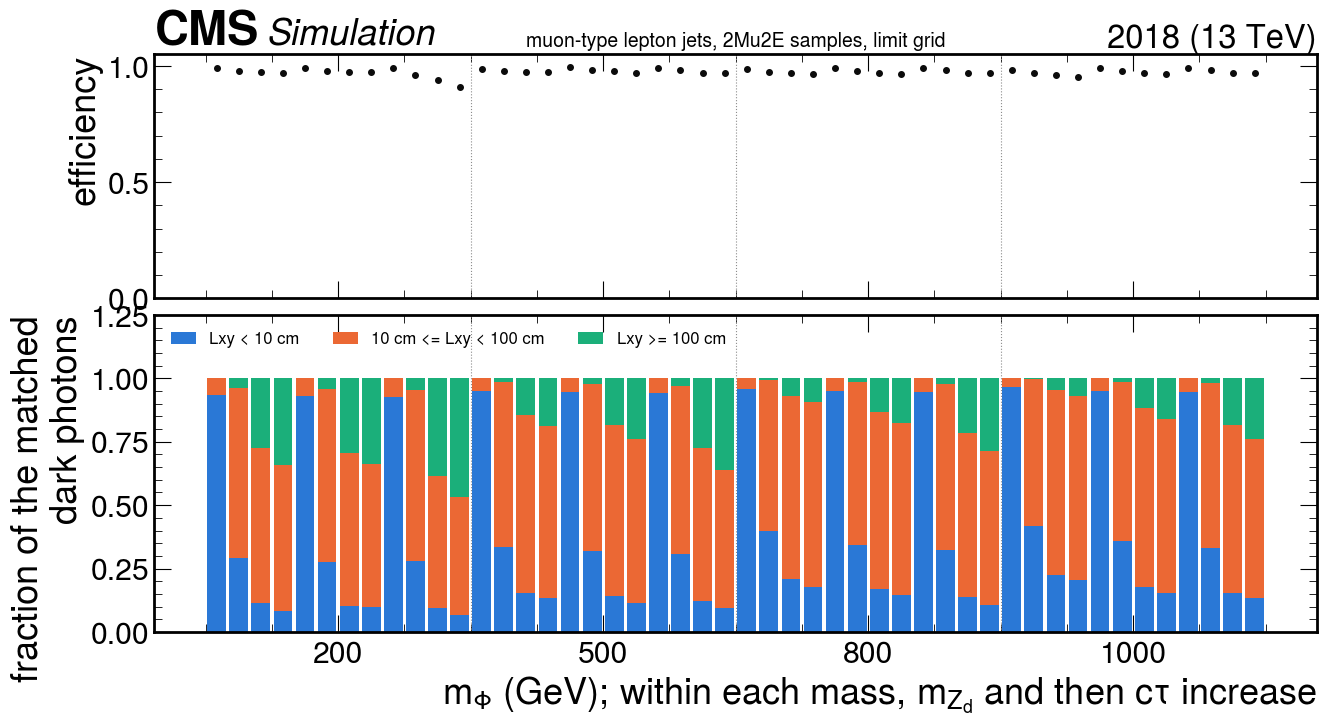

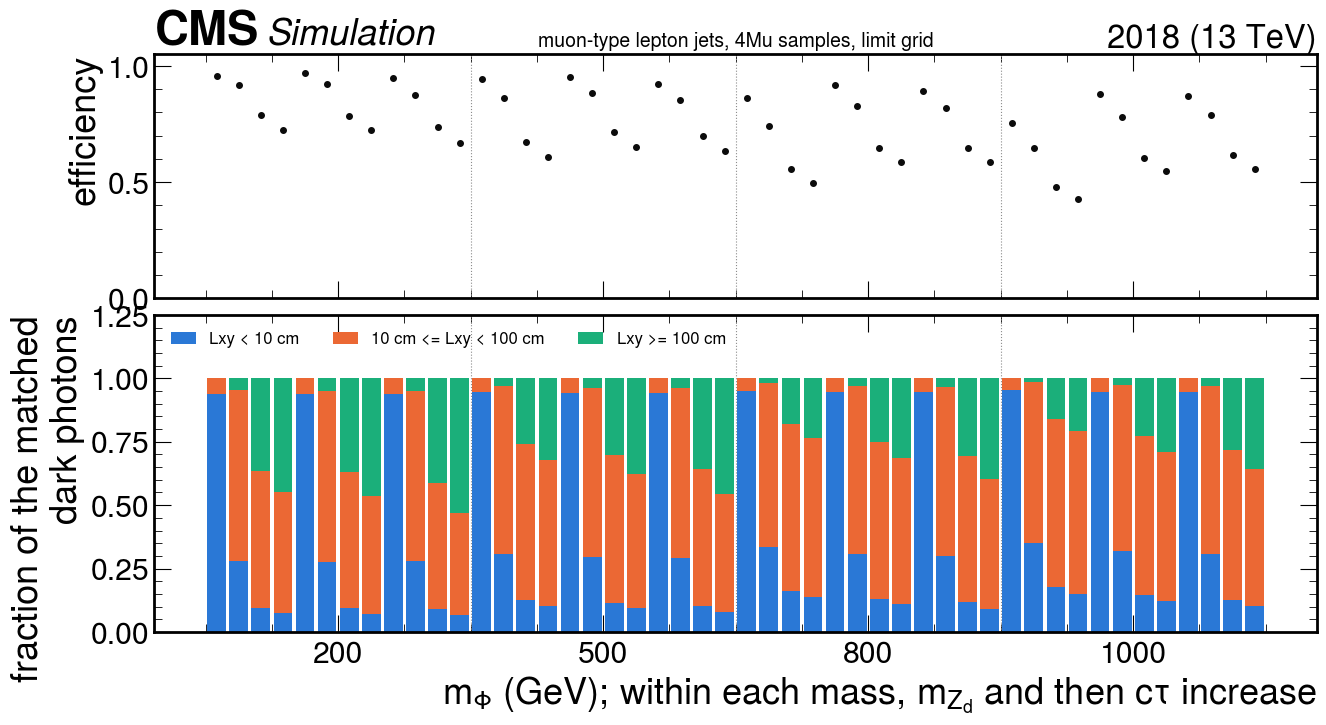

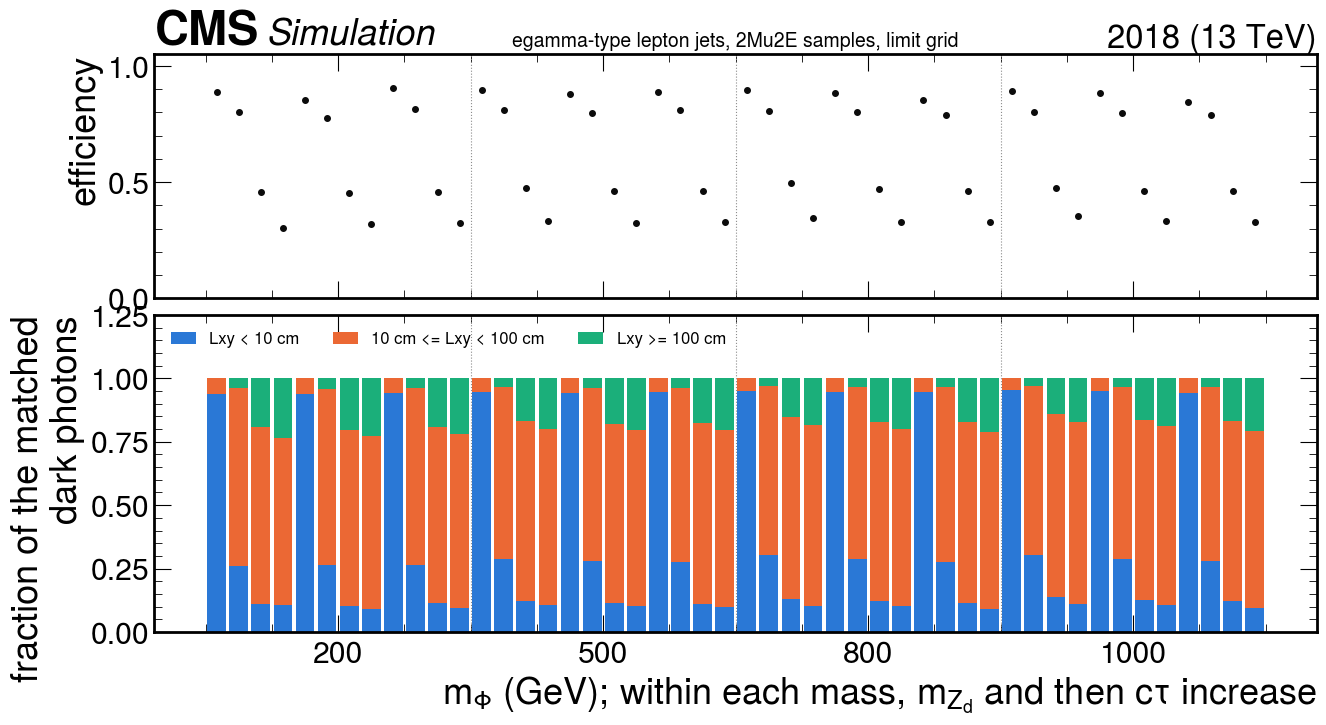

medians over the limit grid:
                     efficiency  Lxy < 10 cm  10 cm <= Lxy < 100 cm  Lxy >= 100 cm
samples lepton_jet                                                                
2Mu2E   egamma-type       0.637        0.197                  0.689          0.091
        muon-type         0.975        0.251                  0.628          0.047
4Mu     muon-type         0.750        0.227                  0.574          0.104


In [5]:
for fs, lj_type in CASES:
    grid = [s for s in points[fs] if s in LIMIT]
    fig = sysstudy.plot_regimes(inputs, grid, lj_type, title=f"{lj_type} lepton jets, {fs} samples, limit grid")
    save(fig, f"regimes_{lj_type}_{fs}")
    plt.show()

rows = []
for fs in points:
    for s in points[fs]:
        for lj_type in inputs[s]:
            eff, fractions = sysstudy.regime_fractions(*inputs[s][lj_type]["lxy"])
            rows.append({"point": s, "lepton_jet": lj_type, "limit_grid": s in LIMIT, "efficiency": eff, **fractions})
table = pd.DataFrame(rows)
table.to_csv(WORK / "efficiency_regimes.csv", index=False)
summary = (table[table.limit_grid].assign(samples=lambda t: t.point.str.split("_").str[0])
           .groupby(["samples", "lepton_jet"])[["efficiency", *sysstudy.LXY_REGIMES]].median())
print("medians over the limit grid:")
print(summary.round(3).to_string())

**Interpretation (run of 2026-11-14).**

The pattern repeats for every bound state mass and dark photon mass: the regime is set by the
lifetime. The limit grid has four lifetimes per mass pair; ranges over the 12 mass pairs of each
final state:

| lifetime (in each mass pair) | $L_{xy}$ < 10 cm | 10 to 100 cm | 100 cm and more | efficiency |
|---|---|---|---|---|
| shortest | 93 to 97% | 3 to 7% | 0% | 0.98 to 0.99 (2Mu2E μ), 0.76 to 0.97 (4Mu μ), 0.85 to 0.91 (egamma) |
| second | 26 to 42% | 58 to 70% | 0 to 5% | 0.96 to 0.98, 0.65 to 0.92, 0.78 to 0.82 |
| third | 9 to 22% | 50 to 73% | 5 to 41% | 0.94 to 0.98, 0.48 to 0.79, 0.45 to 0.50 |
| longest | 7 to 20% | 41 to 73% | 7 to 53% | 0.91 to 0.98, 0.43 to 0.72, 0.30 to 0.36 |

The fractions are of the matched dark photons, the ones whose lepton jets enter the selected
events. Over the whole limit grid, the median point takes 57 to 69% of its lepton jets from the
strip tracker, 20 to 25% from inside the pixel layers and 5 to 10% from beyond 100 cm. The
muon-type lepton jets of the long lifetimes reach furthest out (up to 53% beyond 100 cm in 4Mu,
47% in 2Mu2E). The egamma-type ones stop at 140 cm, so their efficiency at the long lifetimes
(0.30 to 0.36) is low mainly because the later decays give no lepton jet at all.

**For the analysis:** only the shortest lifetime of the limit grid decays mostly inside the
pixel layers. The other three take most of their lepton jets from decays in the strip tracker,
so the measurement that matters most is the displaced one, 10 to 100 cm, for both lepton-jet
types. The prompt control samples of the plan (boosted J/ψ and Υ) cover at best the decays inside
the pixel layers: the shortest lifetime, and 7 to 42% of the lepton jets of the others. For the
muon-type lepton jets of the two longest lifetimes, 5 to 53% (median 18 to 37%) come from beyond
100 cm, at the end of the tracker and past it, where the muons are reconstructed in the muon
system alone: that is the cosmic-muon row of the plan. The table `efficiency_regimes.csv` gives
these fractions per point; they are the weights for a provisional value per regime, as the plan
describes, and later for the measured scale factors.

## 5. What step 1 tells the plan, and what stays open

Written for the run of 2026-11-14 (`lj_reco_eff_v1`, 180 signal points). Step 1 is done; steps 2
and 3 wait on the questions below.

### What step 1 tells the plan

1. **Where the lepton jets come from.** Only the shortest lifetime of each mass pair on the limit
   grid decays mostly inside the pixel layers. The other three take 41 to 73% of their lepton
   jets from the strip tracker (10 to 100 cm), and the muon-type ones of the two longest
   lifetimes up to 53% from beyond 100 cm. The displaced measurements of step 2 therefore matter
   more than the prompt ones: the Z → μμγ conversions for egamma-type lepton jets, and the cosmic
   muons for muon-type ones beyond 100 cm. The weights per point are in `efficiency_regimes.csv`.
2. **The muon-type efficiency is shared with the base selection.** In the 2Mu2E samples it is
   0.97 to 0.99 because the base selection already requires both muons, so the dependence on
   the displacement sits in the event acceptance. A muon-type scale factor measured without that
   condition and applied per lepton jet in both channels, as planned, covers it. The size of the
   effect, and a provisional value, should be read from the 4Mu efficiency (0.91 inside the
   pixel layers, 0.82 from 10 to 100 cm, 0.33 beyond 300 cm), not from the 2Mu2E one.
3. **Binning of the scale factors.** The egamma-type efficiency is described by $L_{xy}$ (and
   $p_T$ near the threshold) and ends at 140 cm. The muon-type one depends on $p_T$ or the
   opening angle as well, so its scale factor needs that second variable to transfer between
   signal points.

### What stays open: questions for the group

Step 1 does not answer these; they stay with the group.

1. **Data approval.** Which control samples may be read: cosmics, Z → μμγ, J/ψ → μμ and
   J/ψ → ee. As with the earlier approvals, the signal region is never read.
2. **Scale-factor granularity.** Per lepton jet or per constituent. This decides the change to
   `Corrections` (step 3).
3. **Provisional value until step 2.** Which published data/simulation differences to take per
   regime. Step 1 now provides the weights (section 4).
4. **New from step 1: the most collimated muon pairs.** The heaviest bound states with the
   lightest dark photon ($m_{Z_d}$ = 0.25 GeV at 800 and 1000 GeV, muons about 0.0006 apart in
   $\Delta R$; 8 points of the limit grid per final state) have the lowest prompt muon-type
   efficiency (0.87 and 0.77 in 4Mu inside the pixel layers), and no dimuon resonance reaches
   that opening angle. How should their uncertainty be set?

### Possible next step (not done)

Split the muon-type lepton jets by constituent (PF muons, DSA muons, both) with the channels that
already exist (`baseNoLj_A_mumu_matched_pflj_highPT`, `..._dsalj_highPT`, `..._pfDsalj_highPT`),
in a new campaign `lj_reco_eff_v2`. It would show whether the muon-type lepton jets from 10 to
100 cm are made of PF muons (closer to the J/ψ row of the plan) or DSA muons (the cosmic row), and
it informs question 2.

Everything goes to EOS, and the local working directory is removed.

In [6]:
sysstudy.upload(WORK, OUTPUT_DIR)
shutil.rmtree(WORK)
print("outputs in", OUTPUT_DIR)

outputs in root://cmseos.fnal.gov//store/user/scampbel/sidm_coffea_outputs/lj_reco_eff_v1_results
